# Lab 5
Time Series Analysis

https://av.tib.eu/media/55272  
https://www.kaggle.com/datasets/abdelghaniaaba/wildfire-prediction-dataset  

By Alex Horyshevskyi

### Setup
Install the libraries

In [56]:
%pip install torch scikit-image scikit-learn statsmodels kagglehub tqdm plotly pandas tabulate numpy matplotlib seaborn pillow prophet scipy --quiet

Note: you may need to restart the kernel to use updated packages.


### Load the libraries

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Time series analysis
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

# Statistical analysis
from scipy import stats

# Machine learning metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

# Deep learning (PyTorch)
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Dataset utilities
import kagglehub
from tqdm import tqdm

from pathlib import Path
from typing import Any
from PIL import Image, ImageFile

# Fix for truncated/corrupted images
ImageFile.LOAD_TRUNCATED_IMAGES = True

from skimage.color import rgb2gray
from skimage.feature import graycomatrix, graycoprops


### Download the dataset

In [58]:
path_to_dataset = kagglehub.dataset_download(
    "abdelghaniaaba/wildfire-prediction-dataset"
)
print("Path to dataset files:", path_to_dataset)

# Folders with images split into wildfire and nowildfire subfolders
base_path = Path(path_to_dataset)
SPLITS = {
    "train": base_path / "train",
    "valid": base_path / "valid",
    "test": base_path / "test",
}

# Image handling
TARGET_SIZE = (128, 128)  # downsample for speed
GREEN_THRESHOLD = 0.05  # heuristic for green fraction
EPS = 1e-6

Path to dataset files: /home/rojikaru/.cache/kagglehub/datasets/abdelghaniaaba/wildfire-prediction-dataset/versions/1


### Feature extraction helpers
Brightness, greenery (NDVI-like), texture (GLCM), and color histograms per image.

In [59]:
def load_image(path: Path) -> np.ndarray | None:
    try:
        with Image.open(path) as img:
            img = img.convert("RGB")
            img = img.resize(TARGET_SIZE)
            return np.asarray(img).astype(np.float32) / 255.0
    except (OSError, IOError, ValueError) as e:
        return None


def brightness_features(img: np.ndarray) -> dict[str, float]:
    gray = rgb2gray(img)
    return {
        "brightness_mean": float(gray.mean()),
        "brightness_std": float(gray.std()),
    }


def greenery_features(img: np.ndarray) -> dict[str, float]:
    r, g, b = img[..., 0], img[..., 1], img[..., 2]
    ndvi_like = (g - r) / (g + r + EPS)
    green_fraction = float((g > (r + b) / 2 + GREEN_THRESHOLD).mean())
    return {
        "green_ndvi_mean": float(ndvi_like.mean()),
        "green_ndvi_std": float(ndvi_like.std()),
        "green_fraction": green_fraction,
    }


def texture_features(img: np.ndarray) -> dict[str, float]:
    gray = (rgb2gray(img) * 255).astype(np.uint8)
    glcm = graycomatrix(
        gray, distances=[2], angles=[0], levels=256, symmetric=True, normed=True
    )
    return {
        "texture_contrast": float(graycoprops(glcm, "contrast")[0, 0]),
        "texture_homogeneity": float(graycoprops(glcm, "homogeneity")[0, 0]),
        "texture_energy": float(graycoprops(glcm, "energy")[0, 0]),
    }


def color_hist_features(img: np.ndarray, bins: int = 16) -> dict[str, float]:
    feats = {}
    for i, channel in enumerate("rgb"):
        hist, _ = np.histogram(img[..., i], bins=bins, range=(0.0, 1.0), density=True)
        for j, val in enumerate(hist):
            feats[f"hist_{channel}_{j}"] = float(val)
    return feats


def extract_features(img: np.ndarray) -> dict[str, Any]:
    feats = {}
    feats.update(brightness_features(img))
    feats.update(greenery_features(img))
    feats.update(texture_features(img))
    feats.update(color_hist_features(img))
    return feats


def parse_label_from_path(path: Path) -> str:
    # Assumes structure split/{wildfire,nowildfire}/image.jpg
    return path.parent.name


def surrogate_timestamp(idx: int, start="2020-01-01") -> pd.Timestamp:
    # Dataset lacks capture timestamps; create ordered surrogate for TS ops.
    return pd.to_datetime(start) + pd.to_timedelta(idx, unit="h")

In [60]:
def collect_images(split_root: Path) -> list[Path]:
    return sorted(split_root.rglob("*.jpg"))


def build_feature_df(split_name, split_root) -> pd.DataFrame:
    paths = collect_images(split_root)
    records = []
    skipped = 0
    for idx, img_path in enumerate(tqdm(paths, desc=f"{split_name} images")):
        img = load_image(img_path)
        if img is None:
            skipped += 1
            continue
        try:
            feats = extract_features(img)
            feats.update(
                {
                    "split": split_name,
                    "label": parse_label_from_path(img_path),
                    "image_path": str(img_path),
                    "timestamp": surrogate_timestamp(idx - skipped),
                }
            )
            records.append(feats)
        except Exception as e:
            skipped += 1
            continue
    if skipped > 0:
        print(f"Skipped {skipped} corrupted/unreadable images in {split_name}")
    return pd.DataFrame(records)


def features_df() -> pd.DataFrame:
    features_csv_path = base_path / "wildfire_features.csv"
    if features_csv_path.exists():
        return pd.read_csv(features_csv_path)

    feature_frames = []
    for split, root in SPLITS.items():
        feature_frames.append(build_feature_df(split, root))

    features_df = pd.concat(feature_frames, ignore_index=True)

    # Scale numeric columns (optional) and save raw features
    numeric_cols = [
        c
        for c in features_df.columns
        if c not in {"split", "label", "image_path", "timestamp"}
    ]
    scaler = StandardScaler()
    features_df[numeric_cols] = scaler.fit_transform(features_df[numeric_cols])

    features_df.to_csv(features_csv_path, index=False)
    print("Saved per-image features to", features_csv_path)

    return features_df

### Time-series aggregation
Aggregates per split by day (surrogate) and class for downstream models.


In [63]:
feat_df = features_df()

# Ensure timestamp is datetime and add date column
feat_df["timestamp"] = pd.to_datetime(feat_df["timestamp"])
feat_df["date"] = feat_df["timestamp"].dt.date

# Daily aggregation per label per split
agg = (
    feat_df.groupby(["split", "label", "date"])
    .mean(numeric_only=True)
    .reset_index()
    .sort_values(["date", "split", "label"])
)
agg.drop([bin for bin in agg.columns if bin.startswith('hist')], axis=1, inplace=True)

agg_csv_path = base_path / "wildfire_timeseries_daily.csv"
agg.to_csv(agg_csv_path, index=False)
print("Saved aggregated daily features to", agg_csv_path)

Saved aggregated daily features to /home/rojikaru/.cache/kagglehub/datasets/abdelghaniaaba/wildfire-prediction-dataset/versions/1/wildfire_timeseries_daily.csv


### Exploratory Data Analysis

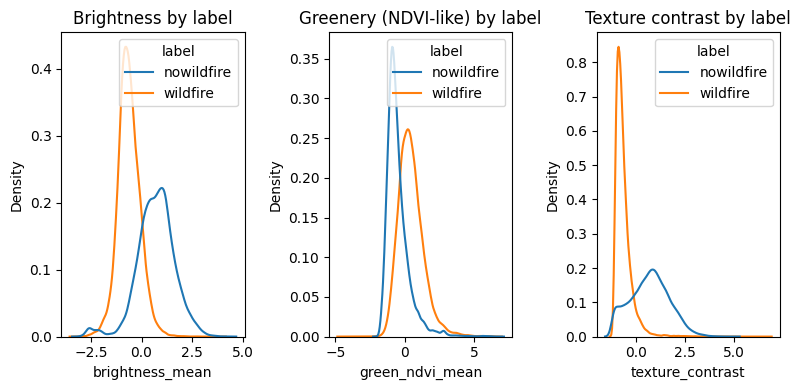

<class 'pandas.core.frame.DataFrame'>
Index: 1790 entries, 0 to 1525
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   split                1790 non-null   object 
 1   label                1790 non-null   object 
 2   date                 1790 non-null   object 
 3   brightness_mean      1790 non-null   float64
 4   brightness_std       1790 non-null   float64
 5   green_ndvi_mean      1790 non-null   float64
 6   green_ndvi_std       1790 non-null   float64
 7   green_fraction       1790 non-null   float64
 8   texture_contrast     1790 non-null   float64
 9   texture_homogeneity  1790 non-null   float64
 10  texture_energy       1790 non-null   float64
dtypes: float64(8), object(3)
memory usage: 167.8+ KB

Aggregated daily features sample:
| split   | label      | date       |   brightness_mean |   brightness_std |   green_ndvi_mean |   green_ndvi_std |   green_fraction |   texture_contrast |   t

In [77]:
fig, axes = plt.subplots(1, 3, figsize=(8, 4))

sns.kdeplot(data=feat_df, x="brightness_mean", hue="label", ax=axes[0])
axes[0].set_title("Brightness by label")

sns.kdeplot(data=feat_df, x="green_ndvi_mean", hue="label", ax=axes[1])
axes[1].set_title("Greenery (NDVI-like) by label")

sns.kdeplot(data=feat_df, x="texture_contrast", hue="label", ax=axes[2])
axes[2].set_title("Texture contrast by label")

plt.tight_layout()
plt.show()

agg.info()

print("\nAggregated daily features sample:")
print(agg.head().to_markdown(index=False))

print("\nStatistical characteristics of the time series features:")
print(agg.describe().to_markdown())

### Time series decomposition

Time series length: 657 observations
Date range: 2021-08-27 00:00:00 to 2023-06-14 00:00:00
Feature: brightness_mean

Decomposition Summary
| Component   |         Mean |    Std Dev |
|:------------|-------------:|-----------:|
| Trend       | -0.632299    | 0.155742   |
| Seasonal    | -1.24536e-05 | 0.00991457 |
| Residual    | -0.000283429 | 0.116025   |


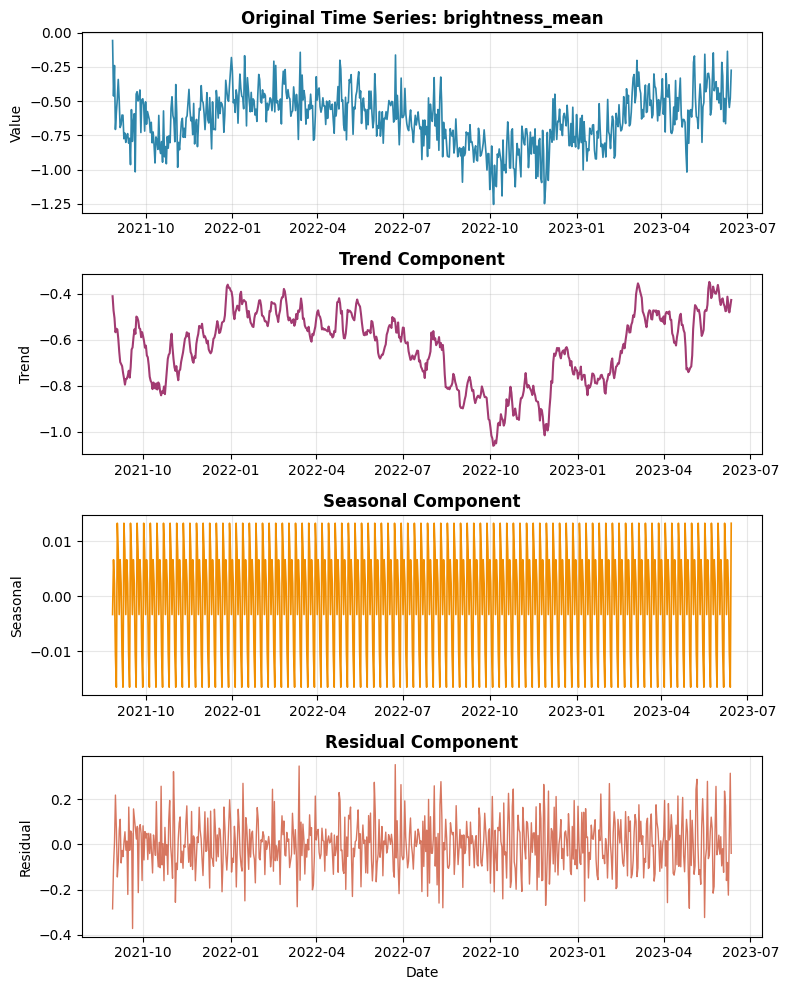

In [71]:
# Prepare time series data for decomposition
# Select train/wildfire combination and use brightness_mean as key feature
ts_data = agg[(agg['split'] == 'train') & (agg['label'] == 'wildfire')].copy()
ts_data['date'] = pd.to_datetime(ts_data['date'])
ts_data = ts_data.set_index('date').sort_index()

# Select the feature for analysis
feature_col = 'brightness_mean'
ts_series = ts_data[feature_col].dropna()

print(f"Time series length: {len(ts_series)} observations")
print(f"Date range: {ts_series.index.min()} to {ts_series.index.max()}")
print(f"Feature: {feature_col}")

# Apply seasonal decomposition
# Using period=7 for weekly seasonality (if data spans multiple weeks)
# Adjust period based on actual data characteristics
period = min(7, len(ts_series) // 2)  # Ensure period is valid for data length

if len(ts_series) >= 2 * period:
    decomposition = seasonal_decompose(ts_series, model='additive', period=period)
    
    # Summary statistics for each component
    decomposition_df = pd.DataFrame({
        'Component': ['Trend', 'Seasonal', 'Residual'],
        'Mean': [
            decomposition.trend.mean(),
            decomposition.seasonal.mean(),
            decomposition.resid.mean()
        ],
        'Std Dev': [
            decomposition.trend.std(),
            decomposition.seasonal.std(),
            decomposition.resid.std()
        ]
    })
    print("\nDecomposition Summary")
    print(decomposition_df.to_markdown(index=False))
    
    # Visualize decomposition components
    fig, axes = plt.subplots(4, 1, figsize=(8, 10))
    
    axes[0].plot(ts_series.index, ts_series.values, color='#2E86AB', linewidth=1.2)
    axes[0].set_title(f'Original Time Series: {feature_col}', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Value')
    axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(decomposition.trend.index, decomposition.trend.values, color='#A23B72', linewidth=1.5)
    axes[1].set_title('Trend Component', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Trend')
    axes[1].grid(True, alpha=0.3)
    
    axes[2].plot(decomposition.seasonal.index, decomposition.seasonal.values, color='#F18F01', linewidth=1.2)
    axes[2].set_title('Seasonal Component', fontsize=12, fontweight='bold')
    axes[2].set_ylabel('Seasonal')
    axes[2].grid(True, alpha=0.3)
    
    axes[3].plot(decomposition.resid.index, decomposition.resid.values, color='#C73E1D', linewidth=1, alpha=0.7)
    axes[3].set_title('Residual Component', fontsize=12, fontweight='bold')
    axes[3].set_ylabel('Residual')
    axes[3].set_xlabel('Date')
    axes[3].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
else:
    print(f"Insufficient data for decomposition. Need at least {2 * period} observations, have {len(ts_series)}.")


### Stationarity check

Testing original time series for stationarity...

ADF Test Results: Original brightness_mean
Test Statistic:    -2.791150
P-Value:           0.059549
Lags Used:         9
Observations:      647

Critical Values:
  1%: -3.440498
  5%: -2.866017
  10%: -2.569154

--- Interpretation ---
P-value (0.0595) >= 0.05: FAIL TO REJECT H0
  The series is NON-STATIONARY (has unit root)


Testing first-differenced series...

ADF Test Results: Differenced brightness_mean
Test Statistic:    -11.072776
P-Value:           0.000000
Lags Used:         12
Observations:      643

Critical Values:
  1%: -3.440561
  5%: -2.866045
  10%: -2.569169

--- Interpretation ---
P-value (0.0000) < 0.05: REJECT H0
  The series is STATIONARY (no unit root)


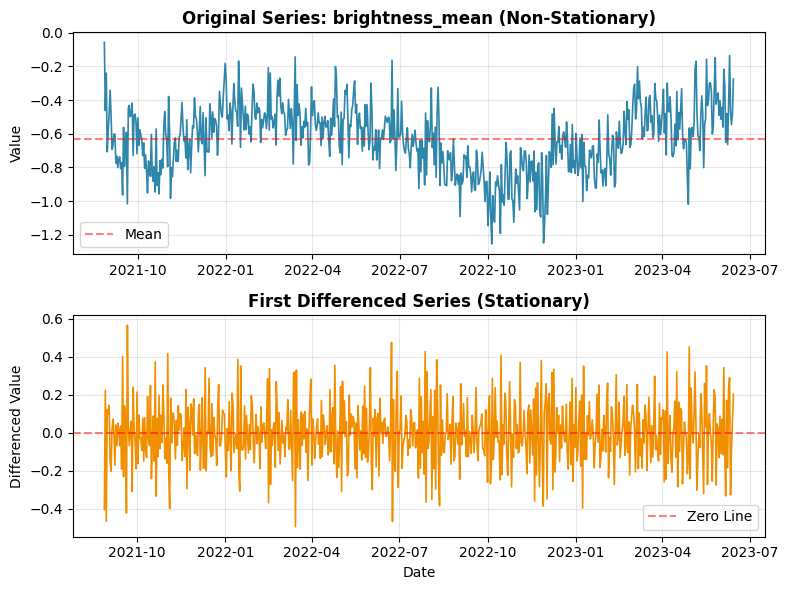


STATIONARITY SUMMARY
Original Series:    Non-Stationary
Differenced Series: Stationary

-> The series is integrated of order 1 (I(1))
  Consider using d=1 in ARIMA models


In [72]:
def perform_adf_test(series, name="Series"):
    """
    Perform Augmented Dickey-Fuller test and display results.
    H0: The series has a unit root (non-stationary)
    H1: The series is stationary
    """
    result = adfuller(series.dropna(), autolag='AIC')
    
    print(f"\n{'='*60}")
    print(f"ADF Test Results: {name}")
    print(f"{'='*60}")
    print(f"Test Statistic:    {result[0]:.6f}")
    print(f"P-Value:           {result[1]:.6f}")
    print(f"Lags Used:         {result[2]}")
    print(f"Observations:      {result[3]}")
    print(f"\nCritical Values:")
    for key, value in result[4].items():
        print(f"  {key}: {value:.6f}")
    
    # Interpretation
    print(f"\n--- Interpretation ---")
    if result[1] < 0.05:
        print(f"P-value ({result[1]:.4f}) < 0.05: REJECT H0")
        print("  The series is STATIONARY (no unit root)")
        is_stationary = True
    else:
        print(f"P-value ({result[1]:.4f}) >= 0.05: FAIL TO REJECT H0")
        print("  The series is NON-STATIONARY (has unit root)")
        is_stationary = False
    
    return is_stationary, result

# Test original series
print("Testing original time series for stationarity...")
is_original_stationary, adf_original = perform_adf_test(ts_series, f"Original {feature_col}")

# Test first-differenced series
ts_diff = ts_series.diff().dropna()
print("\n\nTesting first-differenced series...")
is_diff_stationary, adf_diff = perform_adf_test(ts_diff, f"Differenced {feature_col}")

# Visualize original vs differenced series
fig, axes = plt.subplots(2, 1, figsize=(8, 6))

axes[0].plot(ts_series.index, ts_series.values, color='#2E86AB', linewidth=1.2)
axes[0].set_title(f'Original Series: {feature_col}' + 
                  (' (Stationary)' if is_original_stationary else ' (Non-Stationary)'),
                  fontsize=12, fontweight='bold')
axes[0].set_ylabel('Value')
axes[0].axhline(y=ts_series.mean(), color='red', linestyle='--', alpha=0.5, label='Mean')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(ts_diff.index, ts_diff.values, color='#F18F01', linewidth=1.2)
axes[1].set_title(f'First Differenced Series' +
                  (' (Stationary)' if is_diff_stationary else ' (Non-Stationary)'),
                  fontsize=12, fontweight='bold')
axes[1].set_ylabel('Differenced Value')
axes[1].set_xlabel('Date')
axes[1].axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Zero Line')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Summary
print("\n" + "="*60)
print("STATIONARITY SUMMARY")
print("="*60)
print(f"Original Series:    {'Stationary' if is_original_stationary else 'Non-Stationary'}")
print(f"Differenced Series: {'Stationary' if is_diff_stationary else 'Non-Stationary'}")
if not is_original_stationary and is_diff_stationary:
    print("\n-> The series is integrated of order 1 (I(1))")
    print("  Consider using d=1 in ARIMA models")


### Autocorrelation analysis

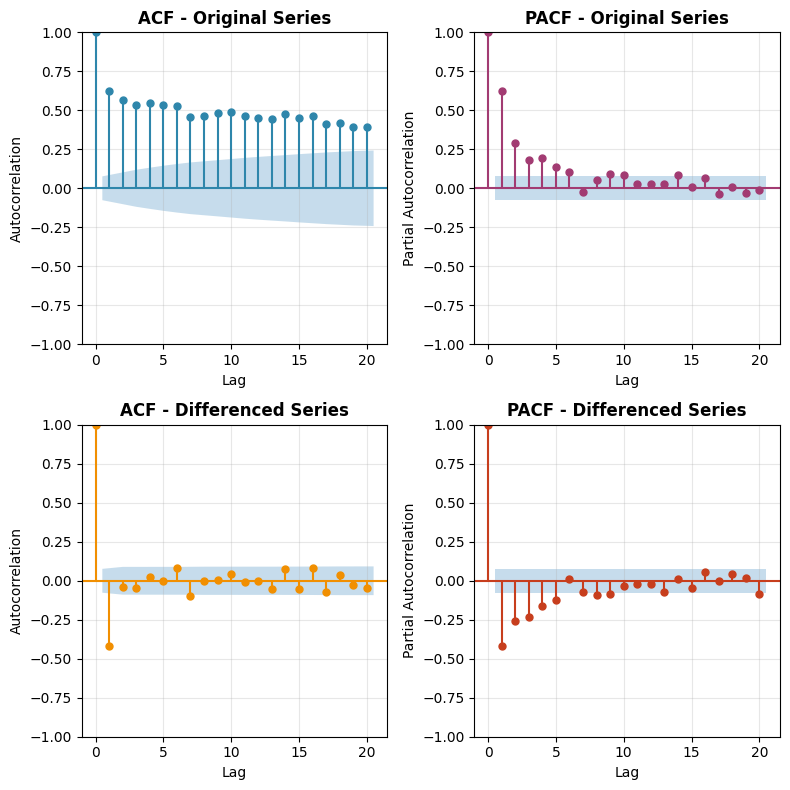

AUTOCORRELATION ANALYSIS SUMMARY
95% Confidence Bound: +/-0.0765

Significant ACF lags (|r| > 0.0765): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Significant PACF lags (|r| > 0.0765): [1, 2, 3, 4, 5, 6, 9, 10, 14]

--- ARIMA Order Suggestions ---
Based on ACF/PACF patterns:
  - If ACF decays gradually and PACF cuts off: AR model (p = # significant PACF lags)
  - If ACF cuts off and PACF decays gradually: MA model (q = # significant ACF lags)
  - If both decay gradually: ARMA model needed

Suggested starting point: ARIMA(p=3, d=1, q=3)


In [75]:
# Autocorrelation Analysis
# ACF helps identify MA(q) order, PACF helps identify AR(p) order

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

# Number of lags to display (adjust based on data length)
n_lags = min(20, len(ts_series) // 3)

# ACF for original series
plot_acf(ts_series.dropna(), lags=n_lags, ax=axes[0, 0], 
         color='#2E86AB', vlines_kwargs={'colors': '#2E86AB', 'linewidth': 1.5})
axes[0, 0].set_title('ACF - Original Series', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Lag')
axes[0, 0].set_ylabel('Autocorrelation')
axes[0, 0].grid(True, alpha=0.3)

# PACF for original series
plot_pacf(ts_series.dropna(), lags=n_lags, ax=axes[0, 1], method='ywm',
          color='#A23B72', vlines_kwargs={'colors': '#A23B72', 'linewidth': 1.5})
axes[0, 1].set_title('PACF - Original Series', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Lag')
axes[0, 1].set_ylabel('Partial Autocorrelation')
axes[0, 1].grid(True, alpha=0.3)

# ACF for differenced series
plot_acf(ts_diff.dropna(), lags=n_lags, ax=axes[1, 0],
         color='#F18F01', vlines_kwargs={'colors': '#F18F01', 'linewidth': 1.5})
axes[1, 0].set_title('ACF - Differenced Series', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Lag')
axes[1, 0].set_ylabel('Autocorrelation')
axes[1, 0].grid(True, alpha=0.3)

# PACF for differenced series
plot_pacf(ts_diff.dropna(), lags=n_lags, ax=axes[1, 1], method='ywm',
          color='#C73E1D', vlines_kwargs={'colors': '#C73E1D', 'linewidth': 1.5})
axes[1, 1].set_title('PACF - Differenced Series', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Lag')
axes[1, 1].set_ylabel('Partial Autocorrelation')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate and display correlation values
acf_vals = acf(ts_series.dropna(), nlags=n_lags)
pacf_vals = pacf(ts_series.dropna(), nlags=n_lags, method='ywm')

# Find significant lags (outside 95% confidence interval)
confidence_bound = 1.96 / np.sqrt(len(ts_series))
significant_acf_lags = [i for i, v in enumerate(acf_vals[1:], 1) if abs(v) > confidence_bound]
significant_pacf_lags = [i for i, v in enumerate(pacf_vals[1:], 1) if abs(v) > confidence_bound]

print("="*60)
print("AUTOCORRELATION ANALYSIS SUMMARY")
print("="*60)
print(f"95% Confidence Bound: +/-{confidence_bound:.4f}")
print(f"\nSignificant ACF lags (|r| > {confidence_bound:.4f}): {significant_acf_lags[:10]}")
print(f"Significant PACF lags (|r| > {confidence_bound:.4f}): {significant_pacf_lags[:10]}")

print("\n--- ARIMA Order Suggestions ---")
print("Based on ACF/PACF patterns:")
print(f"  - If ACF decays gradually and PACF cuts off: AR model (p = # significant PACF lags)")
print(f"  - If ACF cuts off and PACF decays gradually: MA model (q = # significant ACF lags)")
print(f"  - If both decay gradually: ARMA model needed")
print(f"\nSuggested starting point: ARIMA(p={min(len(significant_pacf_lags), 3)}, d={1 if not is_original_stationary else 0}, q={min(len(significant_acf_lags), 3)})")


### Feature analysis

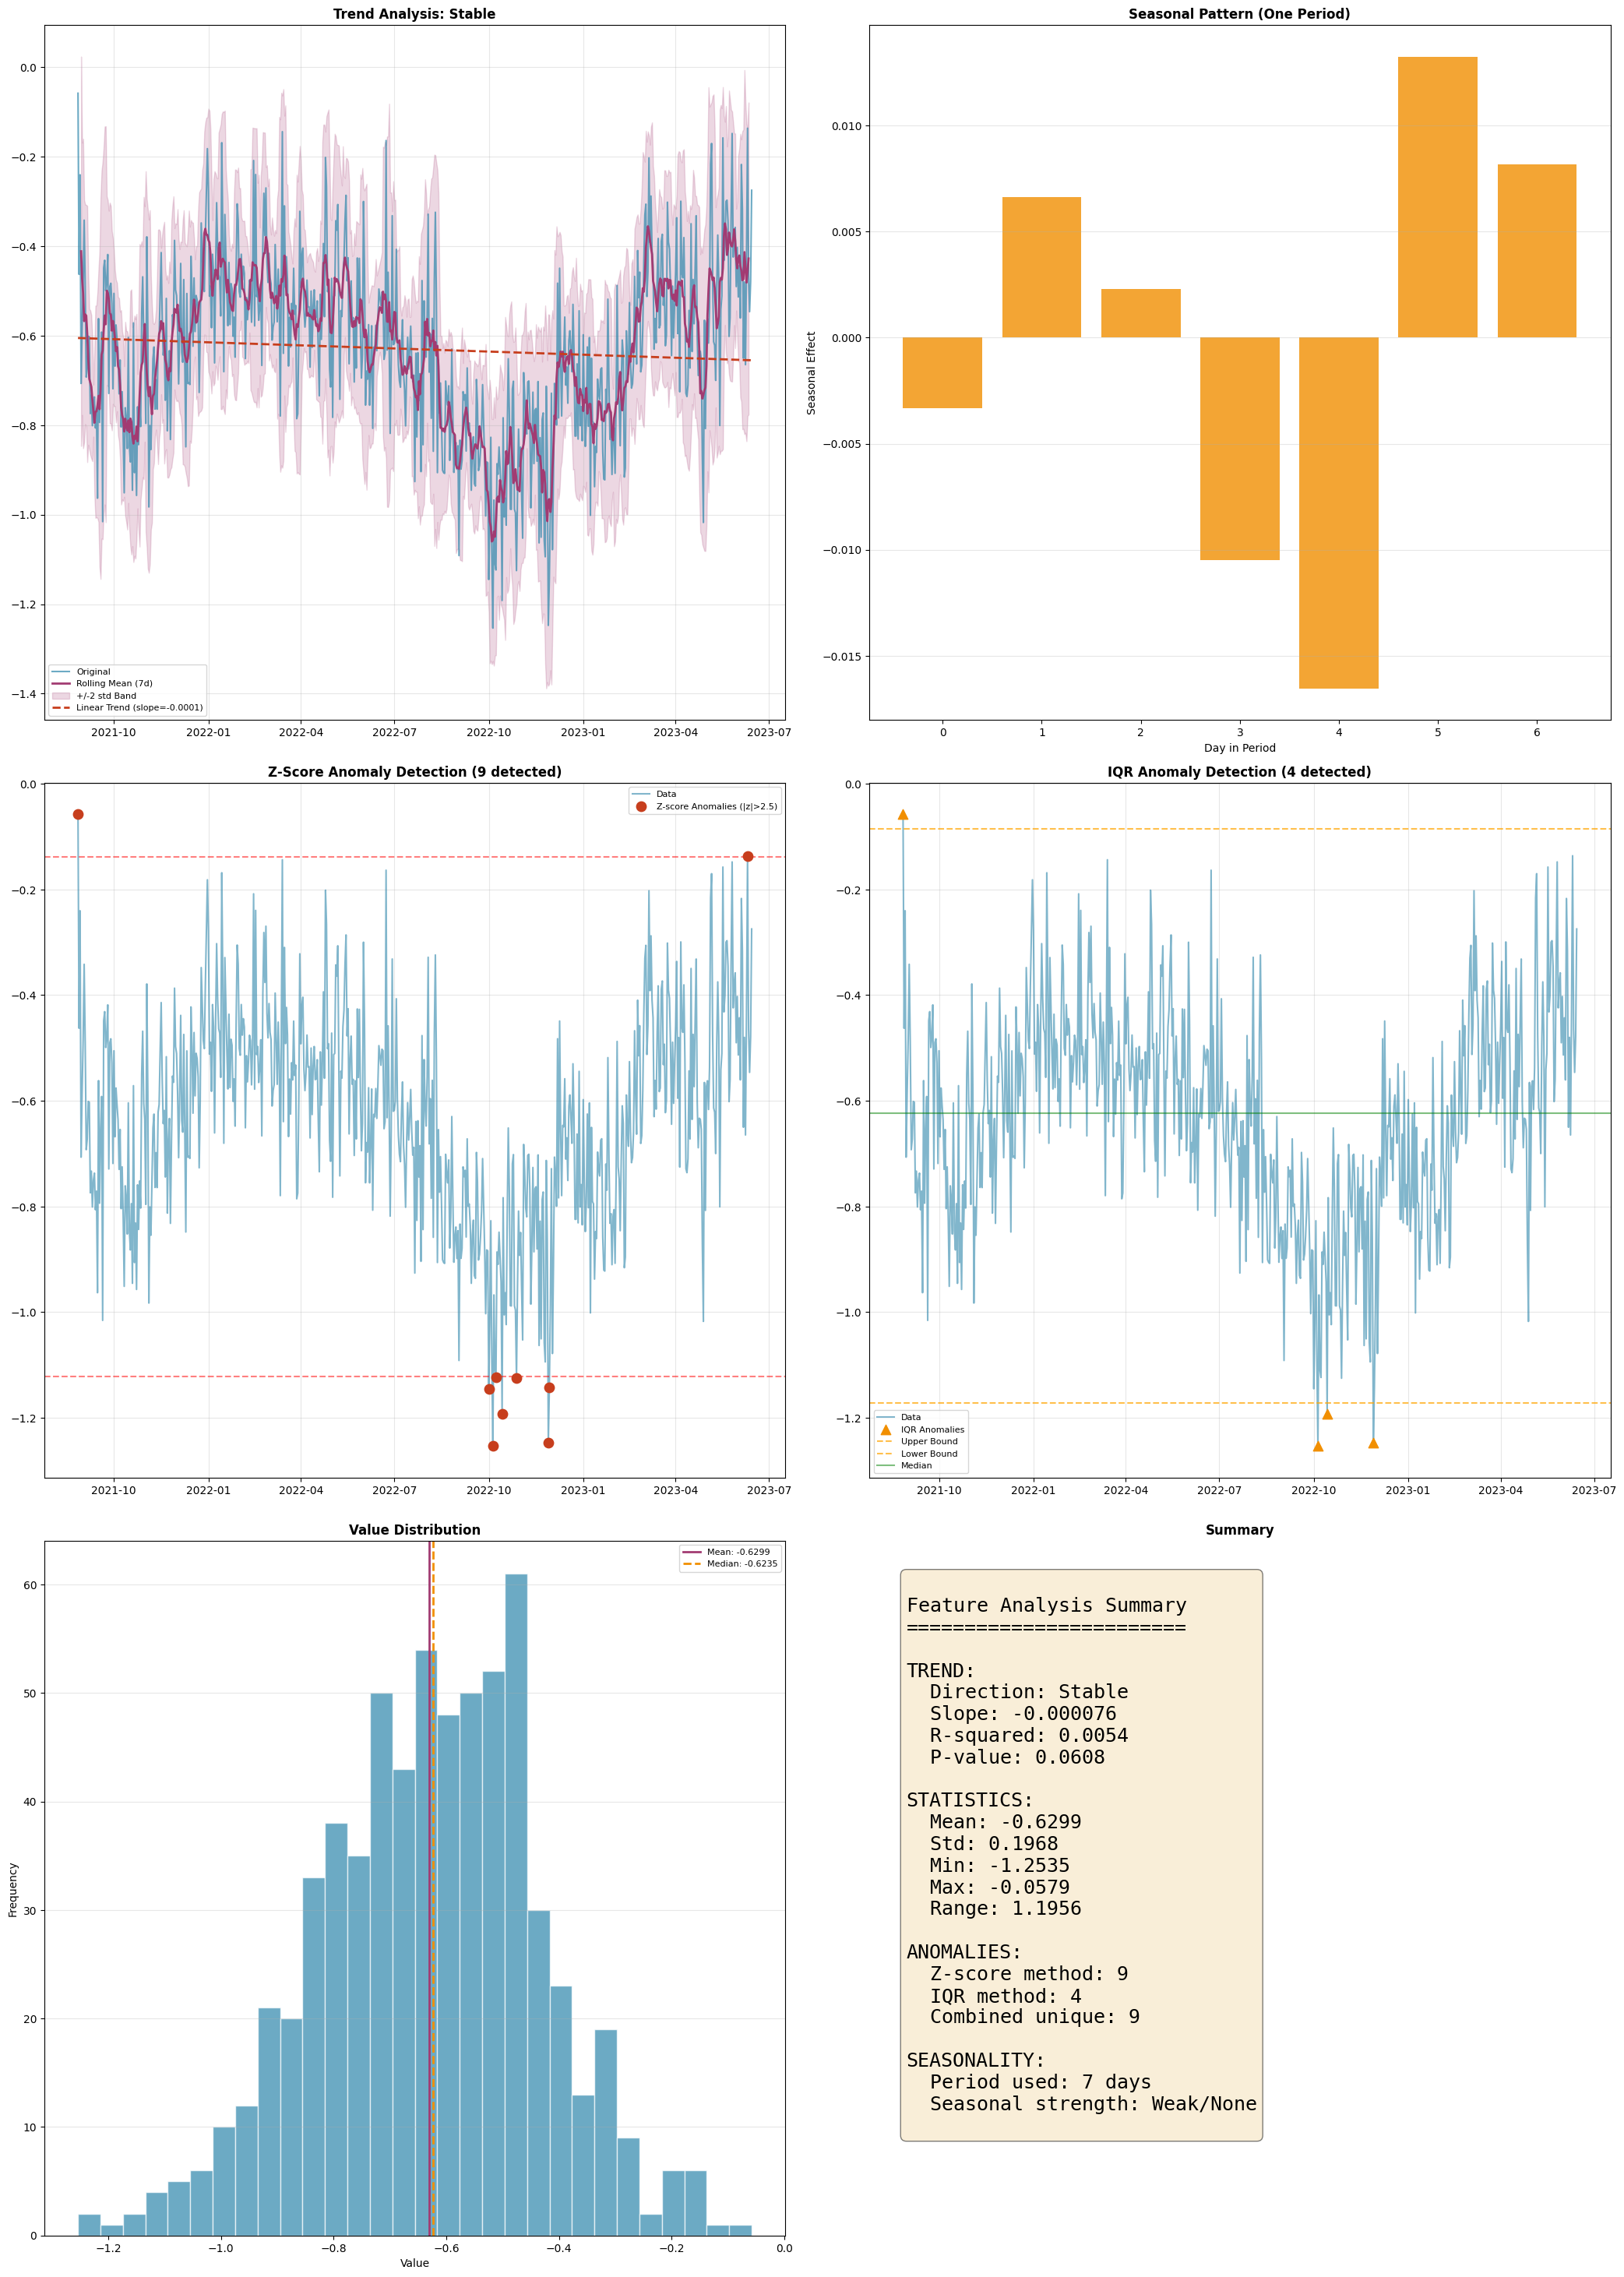


DETECTED ANOMALIES
               Value
date                
2021-08-27 -0.057904
2022-10-01 -1.144914
2022-10-05 -1.253515
2022-10-08 -1.123609
2022-10-14 -1.191794
2022-10-28 -1.125018
2022-11-28 -1.247562
2022-11-29 -1.141924
2023-06-10 -0.136224



Feature Analysis Summary

TREND:
  Direction: Stable
  Slope: -0.000076
  R-squared: 0.0054
  P-value: 0.0608

STATISTICS:
  Mean: -0.6299
  Std: 0.1968
  Min: -1.2535
  Max: -0.0579
  Range: 1.1956

ANOMALIES:
  Z-score method: 9
  IQR method: 4
  Combined unique: 9

SEASONALITY:
  Period used: 7 days
  Seasonal strength: Weak/None



In [ ]:
# Feature Analysis: Trend, Seasonality, Cyclicity, and Anomaly Detection

# 1. Trend Analysis using rolling statistics
window_size = min(7, len(ts_series) // 3)
rolling_mean = ts_series.rolling(window=window_size, center=True).mean()
rolling_std = ts_series.rolling(window=window_size, center=True).std()

# Determine trend direction using linear regression
x_numeric = np.arange(len(ts_series))
slope, intercept, r_value, p_value, std_err = stats.linregress(x_numeric, ts_series.values)

trend_direction = "Increasing" if slope > 0.001 else "Decreasing" if slope < -0.001 else "Stable"

# 2. Anomaly Detection using Z-scores and IQR
z_scores = (ts_series - ts_series.mean()) / ts_series.std()
z_threshold = 2.5
z_anomalies = ts_series[np.abs(z_scores) > z_threshold]

# IQR method
Q1 = ts_series.quantile(0.25)
Q3 = ts_series.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
iqr_anomalies = ts_series[(ts_series < lower_bound) | (ts_series > upper_bound)]

# Combine anomalies from both methods
all_anomaly_indices = z_anomalies.index.union(iqr_anomalies.index)
combined_anomalies = ts_series.loc[all_anomaly_indices]

# 3. Visualization
fig, axes = plt.subplots(3, 2, figsize=(8, 10))

# Plot 1: Trend analysis with rolling statistics
axes[0, 0].plot(ts_series.index, ts_series.values, label='Original', color='#2E86AB', alpha=0.7)
axes[0, 0].plot(rolling_mean.index, rolling_mean.values, label=f'Rolling Mean ({window_size}d)', 
                color='#A23B72', linewidth=2)
axes[0, 0].fill_between(rolling_mean.index, 
                        rolling_mean - 2*rolling_std, 
                        rolling_mean + 2*rolling_std,
                        alpha=0.2, color='#A23B72', label='+/-2 std Band')
# Linear trend line
trend_line = slope * x_numeric + intercept
axes[0, 0].plot(ts_series.index, trend_line, '--', color='#C73E1D', 
                linewidth=2, label=f'Linear Trend (slope={slope:.4f})')
axes[0, 0].set_title(f'Trend Analysis: {trend_direction}', fontsize=12, fontweight='bold')
axes[0, 0].legend(loc='best', fontsize=8)
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Seasonality pattern (if decomposition exists)
if 'decomposition' in dir():
    seasonal_period = decomposition.seasonal[:period]
    axes[0, 1].bar(range(len(seasonal_period)), seasonal_period.values, color='#F18F01', alpha=0.8)
    axes[0, 1].set_title('Seasonal Pattern (One Period)', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Day in Period')
    axes[0, 1].set_ylabel('Seasonal Effect')
    axes[0, 1].grid(True, alpha=0.3, axis='y')
else:
    axes[0, 1].text(0.5, 0.5, 'Decomposition not available', ha='center', va='center')
    axes[0, 1].set_title('Seasonal Pattern', fontsize=12, fontweight='bold')

# Plot 3: Z-score anomalies
axes[1, 0].plot(ts_series.index, ts_series.values, color='#2E86AB', alpha=0.6, label='Data')
axes[1, 0].scatter(z_anomalies.index, z_anomalies.values, color='#C73E1D', s=80, 
                   marker='o', zorder=5, label=f'Z-score Anomalies (|z|>{z_threshold})')
axes[1, 0].axhline(y=ts_series.mean() + z_threshold*ts_series.std(), 
                   color='red', linestyle='--', alpha=0.5)
axes[1, 0].axhline(y=ts_series.mean() - z_threshold*ts_series.std(), 
                   color='red', linestyle='--', alpha=0.5)
axes[1, 0].set_title(f'Z-Score Anomaly Detection ({len(z_anomalies)} detected)', 
                     fontsize=12, fontweight='bold')
axes[1, 0].legend(loc='best', fontsize=8)
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: IQR anomalies (box plot style visualization)
axes[1, 1].plot(ts_series.index, ts_series.values, color='#2E86AB', alpha=0.6, label='Data')
axes[1, 1].scatter(iqr_anomalies.index, iqr_anomalies.values, color='#F18F01', s=80, 
                   marker='^', zorder=5, label=f'IQR Anomalies')
axes[1, 1].axhline(y=upper_bound, color='orange', linestyle='--', alpha=0.7, label='Upper Bound')
axes[1, 1].axhline(y=lower_bound, color='orange', linestyle='--', alpha=0.7, label='Lower Bound')
axes[1, 1].axhline(y=ts_series.median(), color='green', linestyle='-', alpha=0.5, label='Median')
axes[1, 1].set_title(f'IQR Anomaly Detection ({len(iqr_anomalies)} detected)', 
                     fontsize=12, fontweight='bold')
axes[1, 1].legend(loc='best', fontsize=8)
axes[1, 1].grid(True, alpha=0.3)

# Plot 5: Distribution of values
axes[2, 0].hist(ts_series.values, bins=30, color='#2E86AB', alpha=0.7, edgecolor='white')
axes[2, 0].axvline(x=ts_series.mean(), color='#A23B72', linewidth=2, label=f'Mean: {ts_series.mean():.4f}')
axes[2, 0].axvline(x=ts_series.median(), color='#F18F01', linewidth=2, linestyle='--', 
                   label=f'Median: {ts_series.median():.4f}')
axes[2, 0].set_title('Value Distribution', fontsize=12, fontweight='bold')
axes[2, 0].set_xlabel('Value')
axes[2, 0].set_ylabel('Frequency')
axes[2, 0].legend(loc='best', fontsize=8)
axes[2, 0].grid(True, alpha=0.3, axis='y')

# Plot 6: Summary statistics box
summary_text = f"""
Feature Analysis Summary
========================

TREND:
  Direction: {trend_direction}
  Slope: {slope:.6f}
  R-squared: {r_value**2:.4f}
  P-value: {p_value:.4f}

STATISTICS:
  Mean: {ts_series.mean():.4f}
  Std: {ts_series.std():.4f}
  Min: {ts_series.min():.4f}
  Max: {ts_series.max():.4f}
  Range: {ts_series.max() - ts_series.min():.4f}

ANOMALIES:
  Z-score method: {len(z_anomalies)}
  IQR method: {len(iqr_anomalies)}
  Combined unique: {len(combined_anomalies)}

SEASONALITY:
  Period used: {period} days
  Seasonal strength: {'Strong' if 'decomposition' in dir() and decomposition.seasonal.std() > 0.1 else 'Weak/None'}
"""
axes[2, 1].text(0.05, 0.95, summary_text, transform=axes[2, 1].transAxes, 
                fontsize=18, verticalalignment='top', fontfamily='monospace',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
axes[2, 1].axis('off')
axes[2, 1].set_title('Summary', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Print anomaly details
if len(combined_anomalies) > 0:
    print("\n" + "="*60)
    print("DETECTED ANOMALIES")
    print("="*60)
    print(combined_anomalies.to_frame().rename(columns={feature_col: 'Value'}))

print(f"\n\n{summary_text}")

### Analysis approaches

#### ARIMA Model

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Prepare data for modeling
train_size = int(len(ts_series) * 0.8)
train_data = ts_series[:train_size]
test_data = ts_series[train_size:]

print(f"Train size: {len(train_data)}, Test size: {len(test_data)}")

# Helper function to calculate metrics
def calculate_metrics(actual, predicted):
    """Calculate RMSE, MAE, and MAPE"""
    actual = np.array(actual)
    predicted = np.array(predicted)
    
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    
    # MAPE (avoid division by zero)
    mask = actual != 0
    mape = np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100 if mask.any() else np.nan
    
    return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape}

# Store results for comparison
model_results = {}

# Determine ARIMA order based on earlier analysis
# Using suggested values or default (1,1,1) if not enough data
p = min(len(significant_pacf_lags), 2) if 'significant_pacf_lags' in dir() else 1
d = 1 if not is_original_stationary else 0
q = min(len(significant_acf_lags), 2) if 'significant_acf_lags' in dir() else 1

print(f"Fitting ARIMA({p},{d},{q})...")

try:
    arima_model = ARIMA(train_data, order=(p, d, q))
    arima_fit = arima_model.fit()
    
    # Forecast
    arima_forecast = arima_fit.forecast(steps=len(test_data))
    arima_metrics = calculate_metrics(test_data.values, arima_forecast)
    model_results['ARIMA'] = {
        'predictions': arima_forecast,
        'metrics': arima_metrics
    }
    
    print(f"ARIMA Metrics:")
    print(f"  RMSE: {arima_metrics['RMSE']:.4f}")
    print(f"  MAE:  {arima_metrics['MAE']:.4f}")
    print(f"  MAPE: {arima_metrics['MAPE']:.2f}%")
    print(f"\nModel Summary (AIC: {arima_fit.aic:.2f}, BIC: {arima_fit.bic:.2f})")
except Exception as e:
    print(f"ARIMA fitting failed: {e}")
    model_results['ARIMA'] = None

Train size: 525, Test size: 132
Fitting ARIMA(2,1,2)...


/mnt/shared/dev/labs/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/mnt/shared/dev/labs/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/mnt/shared/dev/labs/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


ARIMA Metrics:
  RMSE: 0.3137
  MAE:  0.2770
  MAPE: 74.46%

Model Summary (AIC: -594.02, BIC: -572.71)


#### Prophet Model

In [ ]:
try:
    from prophet import Prophet
    
    # Prepare data for Prophet (requires 'ds' and 'y' columns)
    prophet_train = pd.DataFrame({
        'ds': train_data.index,
        'y': train_data.values
    })
    
    # Initialize and fit Prophet model
    prophet_model = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=True if len(train_data) > 14 else False,
        daily_seasonality=False,
        seasonality_mode='additive'
    )
    prophet_model.fit(prophet_train)
    
    # Create future dataframe for prediction
    future_dates = pd.DataFrame({'ds': test_data.index})
    prophet_forecast = prophet_model.predict(future_dates)
    
    prophet_predictions = prophet_forecast['yhat'].values
    prophet_metrics = calculate_metrics(test_data.values, prophet_predictions)
    model_results['Prophet'] = {
        'predictions': prophet_predictions,
        'metrics': prophet_metrics
    }
    
    print(f"Prophet Metrics:")
    print(f"  RMSE: {prophet_metrics['RMSE']:.4f}")
    print(f"  MAE:  {prophet_metrics['MAE']:.4f}")
    print(f"  MAPE: {prophet_metrics['MAPE']:.2f}%")
    
except ImportError:
    print("Prophet not installed. Install with: pip install prophet")
    print("Skipping Prophet model...")
    model_results['Prophet'] = None
except Exception as e:
    print(f"Prophet fitting failed: {e}")
    model_results['Prophet'] = None

12:23:00 - cmdstanpy - INFO - Chain [1] start processing
12:23:00 - cmdstanpy - INFO - Chain [1] done processing


Prophet Metrics:
  RMSE: 0.2986
  MAE:  0.2620
  MAPE: 70.68%


#### LSTM Model (PyTorch)

Training LSTM on cuda...
Epoch [20/100], Loss: 0.474424
Epoch [40/100], Loss: 0.422266
Epoch [60/100], Loss: 0.311128
Epoch [80/100], Loss: 0.184047
Epoch [100/100], Loss: 0.132724

LSTM Metrics:
  RMSE: 0.1725
  MAE:  0.1361
  MAPE: 35.16%


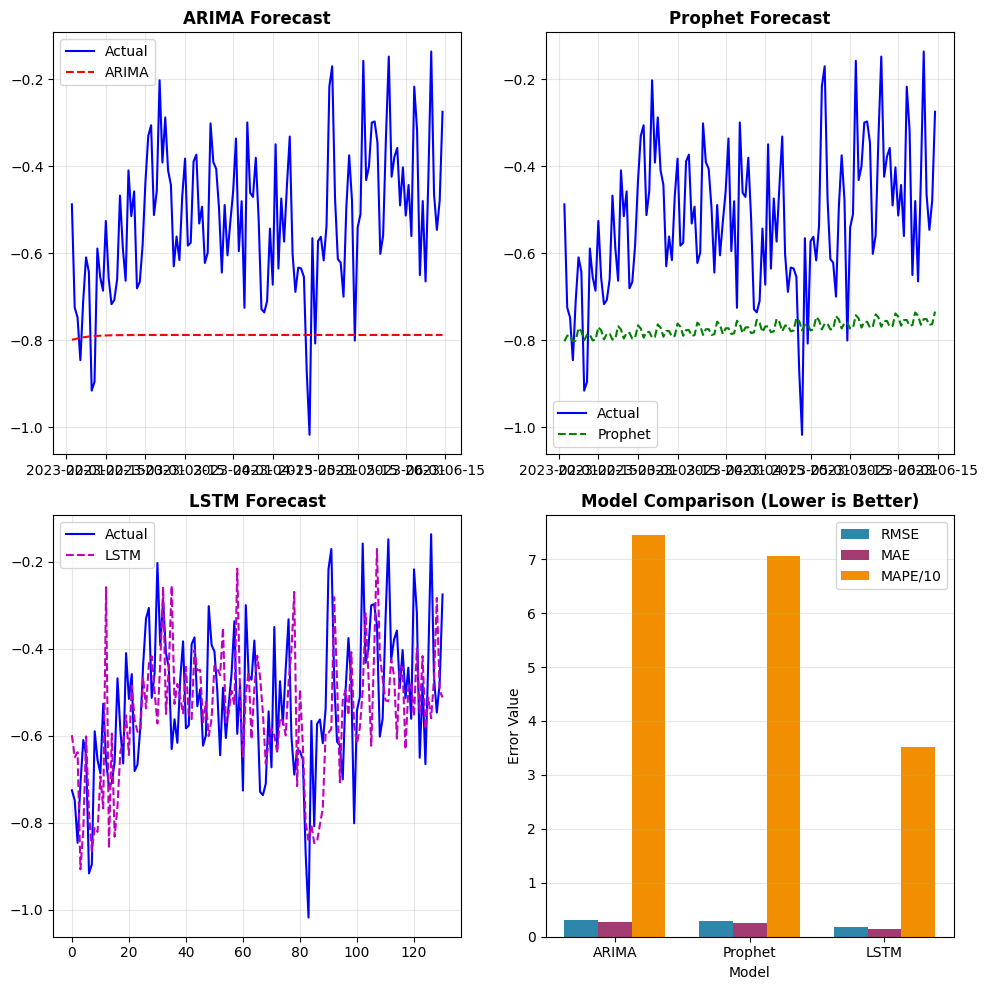


MODEL COMPARISON SUMMARY
| Model   |     RMSE |      MAE |    MAPE |
|:--------|---------:|---------:|--------:|
| ARIMA   | 0.313681 | 0.277028 | 74.458  |
| Prophet | 0.298579 | 0.262016 | 70.6812 |
| LSTM    | 0.172498 | 0.136143 | 35.1649 |

--- Best Model per Metric ---
  RMSE: LSTM (0.1725)
  MAE: LSTM (0.1361)
  MAPE: LSTM (35.1649)


In [76]:
# Define LSTM model architecture
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, num_layers=2, output_size=1):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        # Initialize hidden state
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        
        # Forward pass through LSTM
        out, _ = self.lstm(x, (h0, c0))
        
        # Get output from last time step
        out = self.fc(out[:, -1, :])
        return out

def create_sequences(data, seq_length):
    """Create sequences for LSTM training"""
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

# Prepare data for LSTM
try:
    # Normalize data
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(ts_series.values.reshape(-1, 1)).flatten()
    
    # Create sequences
    seq_length = min(5, len(scaled_data) // 4)  # Sequence length for lookback
    X, y = create_sequences(scaled_data, seq_length)
    
    # Split into train/test
    train_size = int(len(X) * 0.8)
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]
    
    # Convert to PyTorch tensors
    X_train_tensor = torch.FloatTensor(X_train).unsqueeze(-1)  # Add feature dimension
    y_train_tensor = torch.FloatTensor(y_train).unsqueeze(-1)
    X_test_tensor = torch.FloatTensor(X_test).unsqueeze(-1)
    y_test_tensor = torch.FloatTensor(y_test).unsqueeze(-1)
    
    # Create DataLoader
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    
    # Initialize model
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    lstm_model = LSTMModel(input_size=1, hidden_size=32, num_layers=2, output_size=1).to(device)
    
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.01)
    
    # Training loop
    num_epochs = 100
    lstm_model.train()
    
    print(f"Training LSTM on {device}...")
    for epoch in range(num_epochs):
        epoch_loss = 0
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            
            optimizer.zero_grad()
            outputs = lstm_model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        
        if (epoch + 1) % 20 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss/len(train_loader):.6f}")
    
    # Evaluation
    lstm_model.eval()
    with torch.no_grad():
        X_test_device = X_test_tensor.to(device)
        lstm_predictions_scaled = lstm_model(X_test_device).cpu().numpy().flatten()
    
    # Inverse transform predictions
    lstm_predictions = scaler.inverse_transform(lstm_predictions_scaled.reshape(-1, 1)).flatten()
    y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
    
    # Calculate metrics
    lstm_metrics = calculate_metrics(y_test_actual, lstm_predictions)
    model_results['LSTM'] = {
        'predictions': lstm_predictions,
        'metrics': lstm_metrics,
        'actual': y_test_actual
    }
    
    print(f"\nLSTM Metrics:")
    print(f"  RMSE: {lstm_metrics['RMSE']:.4f}")
    print(f"  MAE:  {lstm_metrics['MAE']:.4f}")
    print(f"  MAPE: {lstm_metrics['MAPE']:.2f}%")

except Exception as e:
    print(f"LSTM training failed: {e}")
    model_results['LSTM'] = None

# Model Comparison Visualization
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Plot 1: ARIMA predictions
if model_results.get('ARIMA'):
    axes[0, 0].plot(test_data.index, test_data.values, 'b-', label='Actual', linewidth=1.5)
    axes[0, 0].plot(test_data.index, model_results['ARIMA']['predictions'], 'r--', label='ARIMA', linewidth=1.5)
    axes[0, 0].set_title('ARIMA Forecast', fontsize=12, fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
else:
    axes[0, 0].text(0.5, 0.5, 'ARIMA not available', ha='center', va='center')
    axes[0, 0].set_title('ARIMA Forecast', fontsize=12, fontweight='bold')

# Plot 2: Prophet predictions
if model_results.get('Prophet'):
    axes[0, 1].plot(test_data.index, test_data.values, 'b-', label='Actual', linewidth=1.5)
    axes[0, 1].plot(test_data.index, model_results['Prophet']['predictions'], 'g--', label='Prophet', linewidth=1.5)
    axes[0, 1].set_title('Prophet Forecast', fontsize=12, fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
else:
    axes[0, 1].text(0.5, 0.5, 'Prophet not available', ha='center', va='center')
    axes[0, 1].set_title('Prophet Forecast', fontsize=12, fontweight='bold')

# Plot 3: LSTM predictions
if model_results.get('LSTM'):
    test_indices = range(len(model_results['LSTM']['actual']))
    axes[1, 0].plot(test_indices, model_results['LSTM']['actual'], 'b-', label='Actual', linewidth=1.5)
    axes[1, 0].plot(test_indices, model_results['LSTM']['predictions'], 'm--', label='LSTM', linewidth=1.5)
    axes[1, 0].set_title('LSTM Forecast', fontsize=12, fontweight='bold')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
else:
    axes[1, 0].text(0.5, 0.5, 'LSTM not available', ha='center', va='center')
    axes[1, 0].set_title('LSTM Forecast', fontsize=12, fontweight='bold')

# Plot 4: Model comparison metrics
metrics_data = []
for model_name in ['ARIMA', 'Prophet', 'LSTM']:
    if model_results.get(model_name):
        metrics_data.append({
            'Model': model_name,
            'RMSE': model_results[model_name]['metrics']['RMSE'],
            'MAE': model_results[model_name]['metrics']['MAE'],
            'MAPE': model_results[model_name]['metrics']['MAPE']
        })

if metrics_data:
    metrics_df = pd.DataFrame(metrics_data)
    x = np.arange(len(metrics_df))
    width = 0.25
    
    bars1 = axes[1, 1].bar(x - width, metrics_df['RMSE'], width, label='RMSE', color='#2E86AB')
    bars2 = axes[1, 1].bar(x, metrics_df['MAE'], width, label='MAE', color='#A23B72')
    bars3 = axes[1, 1].bar(x + width, metrics_df['MAPE']/10, width, label='MAPE/10', color='#F18F01')
    
    axes[1, 1].set_xlabel('Model')
    axes[1, 1].set_ylabel('Error Value')
    axes[1, 1].set_title('Model Comparison (Lower is Better)', fontsize=12, fontweight='bold')
    axes[1, 1].set_xticks(x)
    axes[1, 1].set_xticklabels(metrics_df['Model'])
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3, axis='y')
else:
    axes[1, 1].text(0.5, 0.5, 'No models available for comparison', ha='center', va='center')
    axes[1, 1].set_title('Model Comparison', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Print final comparison table
print("\n" + "="*60)
print("MODEL COMPARISON SUMMARY")
print("="*60)
if metrics_data:
    print(pd.DataFrame(metrics_data).to_markdown(index=False))
    
    # Find best model for each metric
    print("\n--- Best Model per Metric ---")
    for metric in ['RMSE', 'MAE', 'MAPE']:
        best_model = min(metrics_data, key=lambda x: x[metric])
        print(f"  {metric}: {best_model['Model']} ({best_model[metric]:.4f})")
else:
    print("No models were successfully trained.")